# Question 7 – Z-Test and Statistical Decision-Making
## Scenario: Data Processing Latency Evaluation

A cloud provider **claims mean latency = 100 ms**. A random sample of **n = 100** requests has **sample mean = 103 ms**. The **population SD σ = 12 ms is known**.

| Task | Description | Marks |
|---|---|---|
| a | Population parameter, sample statistics, Z-test assumptions | 10 |
| b | Null and alternative hypotheses (two-tailed) | 10 |
| c | Significance level and critical values | 10 |
| d | Standard error and Z-statistic | 15 |
| e | Two-tailed p-value | 15 |
| f | 95% confidence interval for the population mean | 15 |
| g | Critical-value vs p-value approach; decision | 15 |
| h | Statistical and practical implications | 10 |

> **How to use:** run all cells in order (Jupyter or Colab). **Exam tip:** change the five numbers in the first code cell and every result updates. At the end there is a reusable `z_test()` function, including one-tailed versions, for variations of this question.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

# ---- Given information ----
mu0   = 100     # claimed population mean (ms) - value under H0
x_bar = 103     # sample mean (ms)
sigma = 12      # KNOWN population standard deviation (ms)
n     = 100     # sample size
alpha = 0.05    # significance level

## (a) Parameter, statistics and assumptions  *(10 marks)*

| Item | Symbol | Value | Type |
|---|---|---|---|
| Population mean latency (unknown, being tested) | μ | ? | **parameter of interest** |
| Claimed / hypothesized mean | μ₀ | 100 ms | value of μ under H₀ |
| Population standard deviation (known) | σ | 12 ms | **population parameter** |
| Sample size | n | 100 | sample information |
| Sample mean | x̄ | 103 ms | **sample statistic** (estimate of μ) |

**Why a Z-test?** We are testing **one population mean**, the population **σ is known**, and the sample is **large (n = 100 ≥ 30)**.

**Assumptions of the one-sample Z-test**
1. **Random sampling:** the 100 requests are a random, representative sample of all requests.
2. **Independence:** the latency of one request does not affect another. (The sample is also < 10% of all requests, so sampling without replacement is fine.)
3. **σ is known** (12 ms) and stable, i.e. the same σ applies now.
4. **Normality of the sampling distribution of x̄:** either latency is normally distributed, or, as here, **n is large enough (n ≥ 30)** for the **Central Limit Theorem** to make x̄ approximately normal, even though latency data is usually right-skewed.
5. The data is measured on a continuous (interval/ratio) scale: milliseconds.

In [2]:
print(f"Population parameter tested : μ (true mean latency); H0 value μ0 = {mu0} ms")
print(f"Known population SD         : σ = {sigma} ms")
print(f"Sample statistics           : n = {n}, x̄ = {x_bar} ms")
print(f"Large-sample condition n>=30: {n >= 30} -> CLT applies, x̄ ~ approximately Normal(μ, σ/√n)")

Population parameter tested : μ (true mean latency); H0 value μ0 = 100 ms
Known population SD         : σ = 12 ms
Sample statistics           : n = 100, x̄ = 103 ms
Large-sample condition n>=30: True -> CLT applies, x̄ ~ approximately Normal(μ, σ/√n)


## (b) Hypotheses (two-tailed)  *(10 marks)*

The question is whether the true mean latency **differs** from the claimed 100 ms, in either direction, so the test is **two-tailed**.

$$H_0: \mu = 100 \text{ ms} \quad \text{(the provider's claim is true)}$$
$$H_1: \mu \neq 100 \text{ ms} \quad \text{(the true mean latency differs from 100 ms)}$$

*(If the question only asked whether latency is **higher** than claimed, it would be one-tailed: H₁: μ > 100. See the extra section at the end.)*

## (c) Significance level and critical values  *(10 marks)*

We use the conventional **α = 0.05** (5% risk of wrongly rejecting a true H₀, a Type I error). For a two-tailed test, α is split equally between the two tails (**α/2 = 0.025 each**):

$$Z_{crit} = \pm Z_{1-\alpha/2} = \pm Z_{0.975}$$

In [3]:
z_crit = stats.norm.ppf(1 - alpha / 2)          # inverse of the standard normal CDF
print(f"α = {alpha}, α/2 = {alpha / 2} in each tail")
print(f"Critical values: ±{z_crit:.4f}  (≈ ±1.96)")
print(f"Rejection region: Z < -{z_crit:.2f}  or  Z > +{z_crit:.2f}")

print("\nOther common levels (two-tailed):")
for a in [0.10, 0.05, 0.01]:
    print(f"   α = {a:.2f} -> ±{stats.norm.ppf(1 - a / 2):.4f}")

α = 0.05, α/2 = 0.025 in each tail
Critical values: ±1.9600  (≈ ±1.96)
Rejection region: Z < -1.96  or  Z > +1.96

Other common levels (two-tailed):
   α = 0.10 -> ±1.6449
   α = 0.05 -> ±1.9600
   α = 0.01 -> ±2.5758


## (d) Standard error and Z-statistic  *(15 marks)*

$$SE = \frac{\sigma}{\sqrt{n}} \qquad\qquad Z = \frac{\bar{x} - \mu_0}{SE}$$

The **standard error** is the standard deviation of the sample mean: how much x̄ would vary from sample to sample. The **Z-statistic** counts how many standard errors the sample mean lies from the claimed mean.

In [4]:
se = sigma / np.sqrt(n)
z = (x_bar - mu0) / se

print(f"SE = σ / √n = {sigma} / √{n} = {sigma} / {np.sqrt(n):.0f} = {se:.4f} ms")
print(f"Z  = (x̄ - μ0) / SE = ({x_bar} - {mu0}) / {se:.4f} = {x_bar - mu0} / {se:.4f} = {z:.4f}")

SE = σ / √n = 12 / √100 = 12 / 10 = 1.2000 ms
Z  = (x̄ - μ0) / SE = (103 - 100) / 1.2000 = 3 / 1.2000 = 2.5000


**Meaning:** the sample mean (103 ms) is **2.5 standard errors above** the claimed mean of 100 ms.

## (e) Two-tailed p-value  *(15 marks)*

$$p = 2 \times P(Z \geq |z|) = 2 \times \left[1 - \Phi(|z|)\right]$$

The p-value is the probability of getting a sample mean **at least this far from 100 ms (in either direction)** if H₀ were true.

In [5]:
p_one_tail = stats.norm.sf(abs(z))           # sf = survival function = 1 - CDF
p_value = 2 * p_one_tail

print(f"Φ({abs(z):.2f}) = {stats.norm.cdf(abs(z)):.6f}")
print(f"P(Z > {abs(z):.2f}) = 1 - {stats.norm.cdf(abs(z)):.6f} = {p_one_tail:.6f}")
print(f"Two-tailed p-value = 2 × {p_one_tail:.6f} = {p_value:.6f}  (≈ {p_value * 100:.2f}%)")

Φ(2.50) = 0.993790
P(Z > 2.50) = 1 - 0.993790 = 0.006210
Two-tailed p-value = 2 × 0.006210 = 0.012419  (≈ 1.24%)


## (f) 95% confidence interval for the population mean  *(15 marks)*

$$\bar{x} \pm Z_{0.975} \times SE = \bar{x} \pm 1.96 \times \frac{\sigma}{\sqrt{n}}$$

In [6]:
moe = z_crit * se                             # margin of error
ci_low, ci_high = x_bar - moe, x_bar + moe

print(f"Margin of error = {z_crit:.4f} × {se:.4f} = {moe:.4f} ms")
print(f"95% CI = {x_bar} ± {moe:.4f} = ({ci_low:.4f}, {ci_high:.4f}) ms")
print(f"Using the rounded 1.96: ({x_bar - 1.96 * se:.3f}, {x_bar + 1.96 * se:.3f}) ms")

# Same result with SciPy
print("SciPy check:", tuple(round(float(v), 4) for v in stats.norm.interval(0.95, loc=x_bar, scale=se)))
print(f"\nIs μ0 = {mu0} inside the CI? {ci_low <= mu0 <= ci_high}")

Margin of error = 1.9600 × 1.2000 = 2.3520 ms
95% CI = 103 ± 2.3520 = (100.6480, 105.3520) ms
Using the rounded 1.96: (100.648, 105.352) ms
SciPy check: (100.648, 105.352)

Is μ0 = 100 inside the CI? False


**Interpretation:** we are 95% confident that the **true mean latency lies between about 100.65 ms and 105.35 ms**. The claimed value of **100 ms lies just outside** this interval (below its lower limit), so the interval is consistent with rejecting H₀.

*(Correct wording: if we repeated the sampling many times, 95% of the intervals built this way would contain the true μ. It does **not** mean there is a 95% probability that μ is in this particular interval.)*

## (g) Critical-value vs p-value approach and decision  *(15 marks)*

In [7]:
print("1) CRITICAL-VALUE APPROACH")
print(f"   Compare |Z| with Z_crit: |{z:.2f}| = {abs(z):.2f} {'>' if abs(z) > z_crit else '<='} {z_crit:.2f}")
print(f"   Z falls in the {'REJECTION' if abs(z) > z_crit else 'ACCEPTANCE'} region -> "
      f"{'Reject H0' if abs(z) > z_crit else 'Fail to reject H0'}")

print("\n2) P-VALUE APPROACH")
print(f"   Compare p with α: p = {p_value:.4f} {'<' if p_value < alpha else '>='} α = {alpha}")
print(f"   -> {'Reject H0' if p_value < alpha else 'Fail to reject H0'}")

print("\n3) CONFIDENCE-INTERVAL APPROACH (bonus)")
print(f"   μ0 = {mu0} is {'outside' if not (ci_low <= mu0 <= ci_high) else 'inside'} the 95% CI "
      f"({ci_low:.2f}, {ci_high:.2f}) -> {'Reject H0' if not (ci_low <= mu0 <= ci_high) else 'Fail to reject H0'}")

print("\n4) SENSITIVITY TO α")
for a in [0.10, 0.05, 0.01]:
    zc = stats.norm.ppf(1 - a / 2)
    print(f"   α = {a:.2f}: Z_crit = ±{zc:.3f} -> {'Reject H0' if abs(z) > zc else 'Fail to reject H0'}")

1) CRITICAL-VALUE APPROACH
   Compare |Z| with Z_crit: |2.50| = 2.50 > 1.96
   Z falls in the REJECTION region -> Reject H0

2) P-VALUE APPROACH
   Compare p with α: p = 0.0124 < α = 0.05
   -> Reject H0

3) CONFIDENCE-INTERVAL APPROACH (bonus)
   μ0 = 100 is outside the 95% CI (100.65, 105.35) -> Reject H0

4) SENSITIVITY TO α
   α = 0.10: Z_crit = ±1.645 -> Reject H0
   α = 0.05: Z_crit = ±1.960 -> Reject H0
   α = 0.01: Z_crit = ±2.576 -> Fail to reject H0


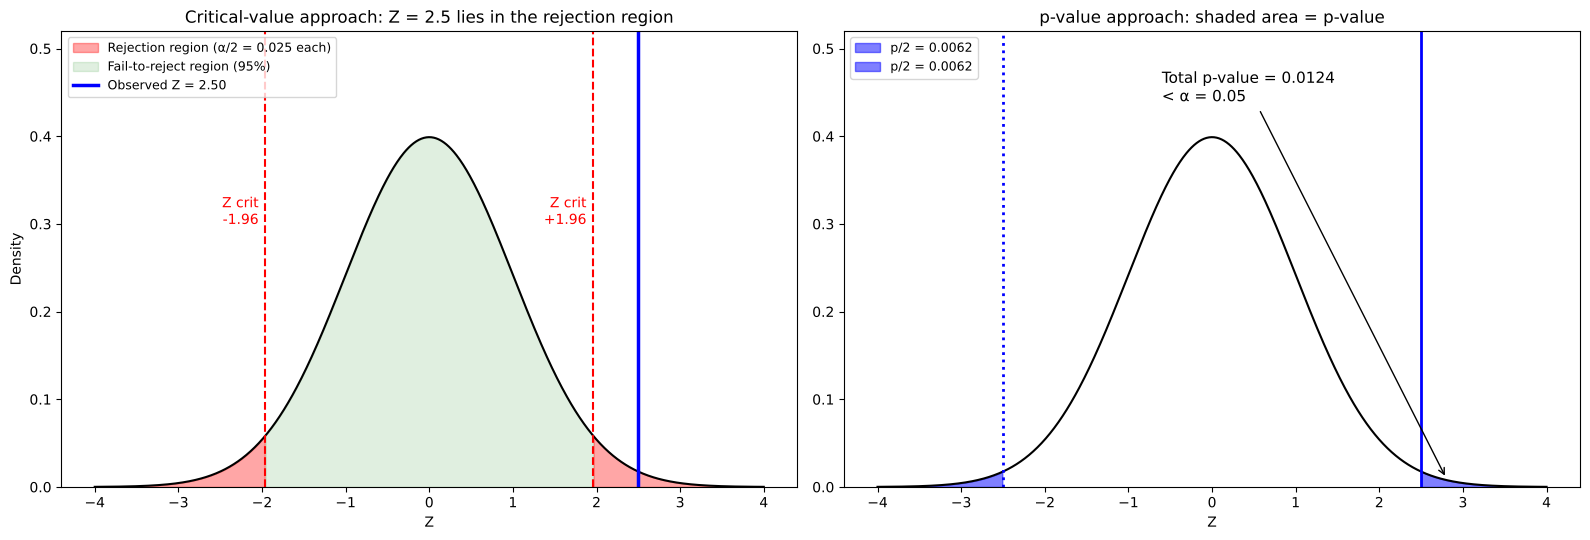

In [8]:
# Visual comparison of both approaches on the standard normal curve
xs = np.linspace(-4, 4, 800)
pdf = stats.norm.pdf(xs)

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))

# Left: critical-value approach (rejection regions defined by α)
ax = axes[0]
ax.plot(xs, pdf, color="black")
ax.fill_between(xs, pdf, where=(xs <= -z_crit), color="red", alpha=0.35, label=f"Rejection region (α/2 = {alpha / 2} each)")
ax.fill_between(xs, pdf, where=(xs >= z_crit), color="red", alpha=0.35)
ax.fill_between(xs, pdf, where=(np.abs(xs) < z_crit), color="green", alpha=0.12, label="Fail-to-reject region (95%)")
ax.axvline(z, color="blue", lw=2.5, label=f"Observed Z = {z:.2f}")
for c in [-z_crit, z_crit]:
    ax.axvline(c, color="red", ls="--")
    ax.text(c - 0.08, 0.30, f"Z crit\n{c:+.2f}", color="red", ha="right")   # label to the left of each line
ax.set_title("Critical-value approach: Z = 2.5 lies in the rejection region")
ax.set_xlabel("Z")
ax.set_ylabel("Density")
ax.set_ylim(0, 0.52)
ax.legend(loc="upper left", fontsize=9)

# Right: p-value approach (area beyond the observed |Z|)
ax = axes[1]
ax.plot(xs, pdf, color="black")
ax.fill_between(xs, pdf, where=(xs >= abs(z)), color="blue", alpha=0.5, label=f"p/2 = {p_one_tail:.4f}")
ax.fill_between(xs, pdf, where=(xs <= -abs(z)), color="blue", alpha=0.5, label=f"p/2 = {p_one_tail:.4f}")
ax.axvline(z, color="blue", lw=2)
ax.axvline(-z, color="blue", lw=2, ls=":")
ax.annotate(f"Total p-value = {p_value:.4f}\n< α = {alpha}", xy=(2.8, 0.01), xytext=(-0.6, 0.44),
            arrowprops=dict(arrowstyle="->"), fontsize=11)
ax.set_title("p-value approach: shaded area = p-value")
ax.set_xlabel("Z")
ax.set_ylim(0, 0.52)
ax.legend(loc="upper left", fontsize=9)

plt.tight_layout()
plt.show()

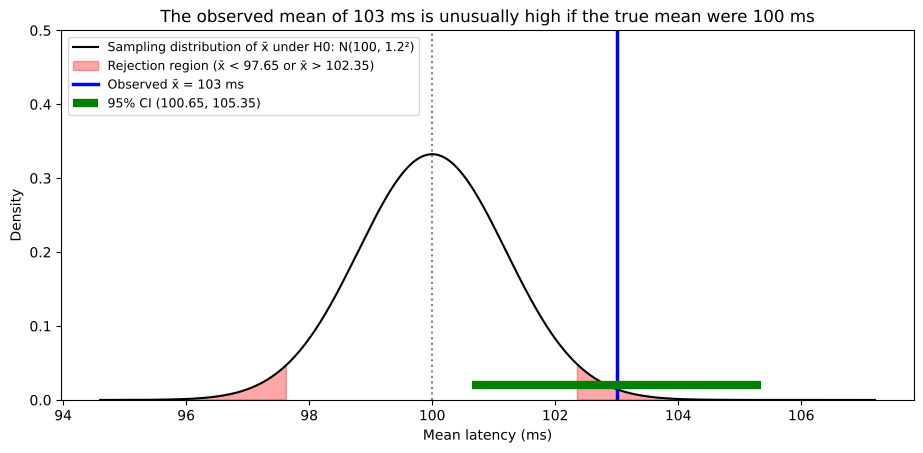

Equivalent rejection rule in ms: reject H0 if x̄ < 97.648 or x̄ > 102.352


In [9]:
# Sampling distribution of x̄ in milliseconds, with the 95% CI
xs_ms = np.linspace(mu0 - 4.5 * se, mu0 + 6 * se, 600)
plt.figure(figsize=(11, 4.8))
plt.plot(xs_ms, stats.norm.pdf(xs_ms, mu0, se), color="black", label=f"Sampling distribution of x̄ under H0: N({mu0}, {se:.1f}²)")
plt.fill_between(xs_ms, stats.norm.pdf(xs_ms, mu0, se), where=(np.abs(xs_ms - mu0) >= z_crit * se),
                 color="red", alpha=0.35, label="Rejection region (x̄ < 97.65 or x̄ > 102.35)")
plt.axvline(x_bar, color="blue", lw=2.5, label=f"Observed x̄ = {x_bar} ms")
plt.hlines(0.02, ci_low, ci_high, color="green", lw=6, label=f"95% CI ({ci_low:.2f}, {ci_high:.2f})")
plt.axvline(mu0, color="grey", ls=":")
plt.xlabel("Mean latency (ms)")
plt.ylabel("Density")
plt.title("The observed mean of 103 ms is unusually high if the true mean were 100 ms")
plt.ylim(0, 0.5)
plt.legend(fontsize=9, loc="upper left")
plt.show()

print(f"Equivalent rejection rule in ms: reject H0 if x̄ < {mu0 - z_crit * se:.3f} or x̄ > {mu0 + z_crit * se:.3f}")

### Comparison of the two approaches

| | Critical-value approach | p-value approach |
|---|---|---|
| What is compared | test statistic **Z** vs **critical value** | **p-value** vs **α** |
| Rule | Reject H₀ if \|Z\| > 1.96 | Reject H₀ if p < 0.05 |
| Here | \|2.50\| > 1.96 → **reject** | 0.0124 < 0.05 → **reject** |
| Output | Yes/no decision at one fixed α | A measure of the **strength of evidence**: the decision can be made at any α |
| Advantage | Simple; works with tables | More informative; shows how close the call is |

**Both approaches always give the same decision** for the same α, because Z > Z_crit exactly when p < α. The confidence-interval approach agrees too: 100 is outside (100.65, 105.35).

### Statistical decision
**Reject H₀ at the 5% significance level.** There is sufficient evidence that the true mean processing latency **differs from 100 ms**, and the data indicates it is **higher** (about 103 ms).

Note: the evidence is significant at α = 0.05 (and at 0.10) but **not** at α = 0.01, because p = 0.0124 > 0.01 and |Z| = 2.5 < 2.576. The result is moderately strong, not overwhelming.

## (h) Statistical and practical implications  *(10 marks)*

In [10]:
effect = x_bar - mu0
d = effect / sigma
print(f"Observed difference : {effect} ms ({effect / mu0 * 100:.1f}% above the claim)")
print(f"Effect size (Cohen's d) = (x̄ - μ0)/σ = {effect}/{sigma} = {d:.2f} -> small effect (0.2 small, 0.5 medium, 0.8 large)")
print(f"Plausible true mean (95% CI): {ci_low:.2f} to {ci_high:.2f} ms -> "
      f"{ci_low - mu0:.2f} to {ci_high - mu0:.2f} ms above the claim")

# Power of this test to detect a true mean of 103 ms (how often we would catch a 3 ms shift)
shift = (x_bar - mu0) / se
power = stats.norm.sf(z_crit - shift) + stats.norm.cdf(-z_crit - shift)
print(f"Power to detect a true mean of {x_bar} ms with n = {n}: {power:.3f}")

# Sample size needed for 80% and 90% power
for target in [0.80, 0.90]:
    n_req = ((z_crit + stats.norm.ppf(target)) * sigma / (x_bar - mu0)) ** 2
    print(f"Sample size for {target:.0%} power to detect a 3 ms shift: n = {int(np.ceil(n_req))}")

Observed difference : 3 ms (3.0% above the claim)
Effect size (Cohen's d) = (x̄ - μ0)/σ = 3/12 = 0.25 -> small effect (0.2 small, 0.5 medium, 0.8 large)
Plausible true mean (95% CI): 100.65 to 105.35 ms -> 0.65 to 5.35 ms above the claim
Power to detect a true mean of 103 ms with n = 100: 0.705
Sample size for 80% power to detect a 3 ms shift: n = 126
Sample size for 90% power to detect a 3 ms shift: n = 169


**Statistical implications**
* The sample gives **statistically significant evidence (Z = 2.50, p = 0.0124)** that the true mean latency is **not 100 ms**. A sample mean of 103 ms would occur only about **1.2% of the time** if the claim were true.
* The 95% CI (100.65, 105.35) ms indicates the true mean is most likely **between about 0.65 ms and 5.35 ms higher** than claimed.
* The conclusion holds at α = 0.05 but not at α = 0.01. There is still a 5% risk of a **Type I error** (rejecting a true claim).
* Power is about 0.70, so a sample of this size would detect a 3 ms shift about 70% of the time. About 126 requests would be needed for 80% power.

**Practical implications for system performance**
* The **provider's claim of 100 ms is not supported**: actual latency appears to be about **3% higher (≈ 103 ms)**.
* The **effect size is small** (d = 0.25). Whether 3 ms matters depends on the application: for batch or web workloads it is probably negligible, but for **real-time or latency-sensitive services** (trading, streaming, IoT control loops, chained micro-service calls where delays add up) it can matter, especially if an SLA promises ≤ 100 ms.
* **Statistical significance ≠ practical importance.** With a large sample even small differences become significant, so the business decision should depend on SLA thresholds and cost, not on the p-value alone.

**Recommended actions:** (1) report the finding to the provider and ask for an explanation, or renegotiate the SLA; (2) monitor latency continuously, including **tail percentiles (p95/p99)**, not just the mean; (3) investigate the causes (network load, peak hours, region, resource contention); (4) confirm with a fresh sample, and check that σ = 12 ms still holds. If σ is not truly known, use a **one-sample t-test** with the sample SD.

---
## Extra: reusable Z-test function (for variations in the exam)

The exam may change the numbers, ask for a **one-tailed** test (e.g. "is latency **greater** than 100 ms?"), or use a different α. This function handles all of these.

* `alternative="two-sided"` → H₁: μ ≠ μ₀
* `alternative="greater"` → H₁: μ > μ₀ (right-tailed, critical value +1.645 at α = 0.05)
* `alternative="less"` → H₁: μ < μ₀ (left-tailed, critical value −1.645 at α = 0.05)

In [11]:
def z_test(x_bar, mu0, sigma, n, alpha=0.05, alternative="two-sided", conf=0.95):
    se = sigma / np.sqrt(n)
    z = (x_bar - mu0) / se
    if alternative == "two-sided":
        p = 2 * stats.norm.sf(abs(z))
        zc = stats.norm.ppf(1 - alpha / 2)
        reject = abs(z) > zc
        crit = f"±{zc:.4f}"
    elif alternative == "greater":
        p = stats.norm.sf(z)
        zc = stats.norm.ppf(1 - alpha)
        reject = z > zc
        crit = f"+{zc:.4f}"
    elif alternative == "less":
        p = stats.norm.cdf(z)
        zc = stats.norm.ppf(alpha)
        reject = z < zc
        crit = f"{zc:.4f}"
    else:
        raise ValueError("alternative must be 'two-sided', 'greater' or 'less'")
    zci = stats.norm.ppf(1 - (1 - conf) / 2)
    print(f"H0: μ = {mu0}   H1: μ {'≠' if alternative == 'two-sided' else '>' if alternative == 'greater' else '<'} {mu0}")
    print(f"SE = {se:.4f}, Z = {z:.4f}, critical value = {crit}, p-value = {p:.6f}")
    print(f"{conf:.0%} CI for μ: ({x_bar - zci * se:.4f}, {x_bar + zci * se:.4f})")
    print("Decision:", "REJECT H0" if reject else "FAIL TO REJECT H0", f"at α = {alpha}\n")
    return z, p

z_test(103, 100, 12, 100, alternative="two-sided")    # this question
z_test(103, 100, 12, 100, alternative="greater")      # one-tailed version: is latency HIGHER than claimed?
z_test(103, 100, 12, 100, alpha=0.01, conf=0.99);     # stricter level (99% CI); ";" hides the returned values

H0: μ = 100   H1: μ ≠ 100
SE = 1.2000, Z = 2.5000, critical value = ±1.9600, p-value = 0.012419
95% CI for μ: (100.6480, 105.3520)
Decision: REJECT H0 at α = 0.05

H0: μ = 100   H1: μ > 100
SE = 1.2000, Z = 2.5000, critical value = +1.6449, p-value = 0.006210
95% CI for μ: (100.6480, 105.3520)
Decision: REJECT H0 at α = 0.05

H0: μ = 100   H1: μ ≠ 100
SE = 1.2000, Z = 2.5000, critical value = ±2.5758, p-value = 0.012419
99% CI for μ: (99.9090, 106.0910)
Decision: FAIL TO REJECT H0 at α = 0.01

